# Sales order data exploration
Use this notebook to explore sales order data

In [4]:
 from pyspark.sql.types import *

 orderSchema = StructType([
     StructField("SalesOrderNumber", StringType()),
     StructField("SalesOrderLineNumber", IntegerType()),
     StructField("OrderDate", DateType()),
     StructField("CustomerName", StringType()),
     StructField("Email", StringType()),
     StructField("Item", StringType()),
     StructField("Quantity", IntegerType()),
     StructField("UnitPrice", FloatType()),
     StructField("Tax", FloatType())
 ])

 df = spark.read.format("csv").schema(orderSchema).load("Files/orders/*.csv")

 display(df)

StatementMeta(, 80808d46-99b1-46b6-bdf4-f80fa6107592, 6, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 08419bd5-c3e5-455c-ad36-4a229ac8e482)

In [8]:
customers = df.select("CustomerName", "Email").where(df['Item']=='Road-250 Red, 52')

print(customers.count())
print(customers.distinct().count())

display(customers.distinct())

StatementMeta(, 80808d46-99b1-46b6-bdf4-f80fa6107592, 10, Finished, Available, Finished, False)

133
133


SynapseWidget(Synapse.DataFrame, a3e3dce5-c954-4cf1-a675-740a213b2efc)

In [9]:
from pyspark.sql.functions import *

yearlySales = df.select(year(col("OrderDate")).alias("Year")).groupBy("Year").count().orderBy("Year")

display(yearlySales)

StatementMeta(, 80808d46-99b1-46b6-bdf4-f80fa6107592, 11, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 527dcdd4-b255-494a-902b-06cb2c94727b)

In [10]:
from pyspark.sql.functions import *

# Create Year and Month columns
transformed_df = df.withColumn("Year", year(col("OrderDate"))).withColumn("Month", month(col("OrderDate")))

# Create the new FirstName and LastName fields
transformed_df = transformed_df.withColumn("FirstName", split(col("CustomerName"), " ").getItem(0)).withColumn("LastName", split(col("CustomerName"), " ").getItem(1))

# Filter and reorder columns
transformed_df = transformed_df["SalesOrderNumber", "SalesOrderLineNumber", "OrderDate", "Year", "Month", "FirstName", "LastName", "Email", "Item", "Quantity", "UnitPrice", "Tax"]

# Display the first five orders
display(transformed_df.limit(5))

StatementMeta(, 80808d46-99b1-46b6-bdf4-f80fa6107592, 12, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 2e61ecb3-5ab2-4cc3-9499-42ced38678af)

In [16]:
transformed_df.write.mode("overwrite").parquet('Files/transformed_data/orders')

print ("Transformed data saved!")

StatementMeta(, 80808d46-99b1-46b6-bdf4-f80fa6107592, 18, Finished, Available, Finished, False)

Transformed data saved!


In [17]:
orders_df = spark.read.format("parquet").load("Files/transformed_data/orders")
display(orders_df)

StatementMeta(, 80808d46-99b1-46b6-bdf4-f80fa6107592, 19, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 4e66b34f-c52e-4887-a114-579c2bd76a57)

In [18]:
orders_df.write.partitionBy("Year","Month").mode("overwrite").parquet("Files/partitioned_data")

print ("Transformed data saved!")

StatementMeta(, 80808d46-99b1-46b6-bdf4-f80fa6107592, 20, Finished, Available, Finished, False)

Transformed data saved!


In [19]:
orders_2021_df = spark.read.format("parquet").load("Files/partitioned_data/Year=2021/Month=*")

display(orders_2021_df)

StatementMeta(, 80808d46-99b1-46b6-bdf4-f80fa6107592, 21, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 43d31c20-e3da-464a-ae9a-be834ff6a7ab)

In [20]:
 # Create a new table
 df.write.format("delta").saveAsTable("salesorders")

 # Get the table description
 spark.sql("DESCRIBE EXTENDED salesorders").show(truncate=False)

StatementMeta(, 80808d46-99b1-46b6-bdf4-f80fa6107592, 22, Finished, Available, Finished, False)

+----------------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-------+
|col_name                    |data_type                                                                                                                                                                                                                                                                                               |comment|
+----------------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-

In [21]:
df = spark.sql("SELECT * FROM Irina_Lakehouse.dbo.salesorders LIMIT 1000")
display(df)

StatementMeta(, 80808d46-99b1-46b6-bdf4-f80fa6107592, 23, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 29cc1479-d1f5-497e-ae9b-6872028b4cc9)

In [22]:
%%sql
SELECT YEAR(OrderDate) AS OrderYear,
       SUM((UnitPrice * Quantity) + Tax) AS GrossRevenue
FROM salesorders
GROUP BY YEAR(OrderDate)
ORDER BY OrderYear;

StatementMeta(, 80808d46-99b1-46b6-bdf4-f80fa6107592, 24, Finished, Available, Finished, False)

<Spark SQL result set with 3 rows and 2 fields>

In [23]:
%%sql
SELECT * FROM salesorders

StatementMeta(, 80808d46-99b1-46b6-bdf4-f80fa6107592, 25, Finished, Available, Finished, False)

<Spark SQL result set with 1000 rows and 9 fields>

In [24]:
sqlQuery = "SELECT CAST(YEAR(OrderDate) AS CHAR(4)) AS OrderYear, \
                SUM((UnitPrice * Quantity) + Tax) AS GrossRevenue, \
                COUNT(DISTINCT SalesOrderNumber) AS YearlyCounts \
            FROM salesorders \
            GROUP BY CAST(YEAR(OrderDate) AS CHAR(4)) \
            ORDER BY OrderYear"
df_spark = spark.sql(sqlQuery)
df_spark.show()

StatementMeta(, 80808d46-99b1-46b6-bdf4-f80fa6107592, 27, Finished, Available, Finished, False)

+---------+--------------------+------------+
|OrderYear|        GrossRevenue|YearlyCounts|
+---------+--------------------+------------+
|     2019|   4172169.969970703|        1201|
|     2020|   6882259.268127441|        2733|
|     2021|1.1547835291696548E7|       12525|
+---------+--------------------+------------+



StatementMeta(, 80808d46-99b1-46b6-bdf4-f80fa6107592, 30, Finished, Available, Finished, False)

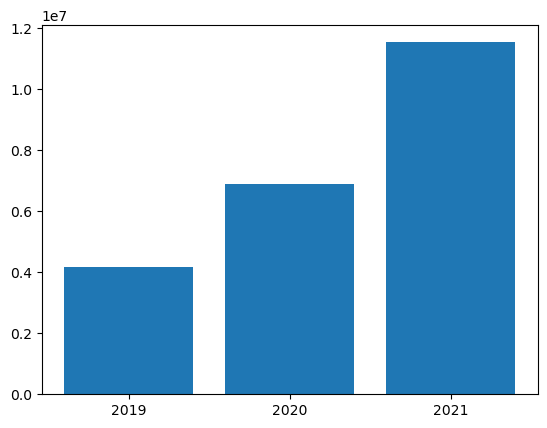

In [25]:
from matplotlib import pyplot as plt

# matplotlib requires a Pandas dataframe, not a Spark one
df_sales = df_spark.toPandas()

# Create a bar plot of revenue by year
plt.bar(x=df_sales['OrderYear'], height=df_sales['GrossRevenue'])

# Display the plot
plt.show()

StatementMeta(, 80808d46-99b1-46b6-bdf4-f80fa6107592, 39, Finished, Available, Finished, False)

<Figure size 640x480 with 0 Axes>

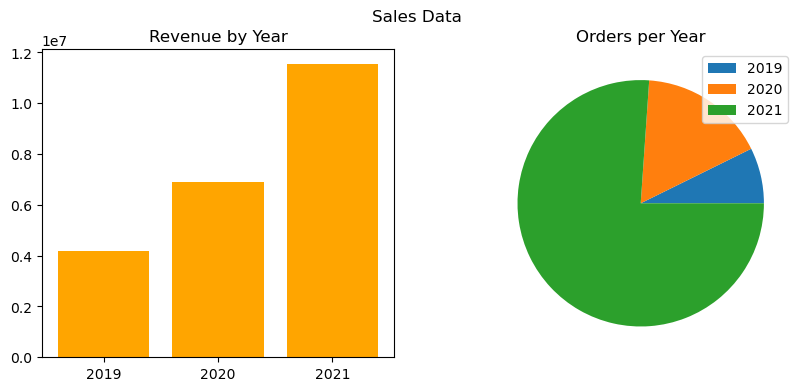

In [28]:
from matplotlib import pyplot as plt

# Clear the plot area
plt.clf()

# Create a figure for 2 subplots (1 row, 2 columns)
fig, ax = plt.subplots(1, 2, figsize = (10,4))

# Create a bar plot of revenue by year on the first axis
ax[0].bar(x=df_sales['OrderYear'], height=df_sales['GrossRevenue'], color='orange')
ax[0].set_title('Revenue by Year')

# Create a pie chart of yearly order counts on the second axis
ax[1].pie(df_sales['YearlyCounts'])
ax[1].set_title('Orders per Year')
ax[1].legend(df_sales['OrderYear'])

# Add a title to the Figure
fig.suptitle('Sales Data')

# Show the figure
plt.show()

StatementMeta(, 80808d46-99b1-46b6-bdf4-f80fa6107592, 48, Finished, Available, Finished, False)

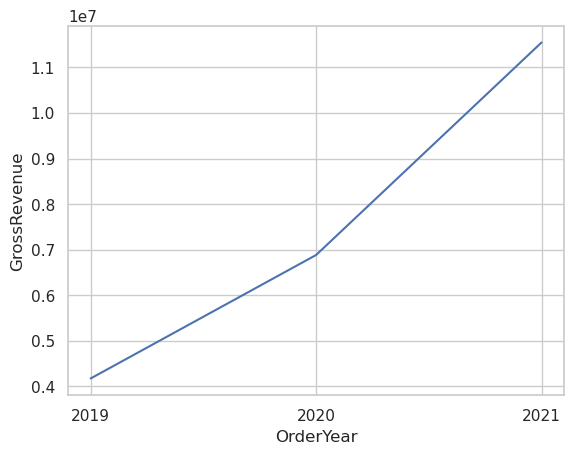

In [31]:
 import seaborn as sns

 # Clear the plot area
 plt.clf()

 # Create a line chart
 ax = sns.lineplot(x="OrderYear", y="GrossRevenue", data=df_sales)

 plt.show()